# 01 - Ingestão, Tratamento Anti-GIGO e EDA
**Projeto:** Confiança, transparência da comunicação e churn em crises bancárias (Etapa 2)

**O que este notebook faz, na ordem:**
1. Lê o CSV bruto do Google Forms (sem alterá-lo)
2. Renomeia as colunas e converte os tipos
3. Aplica o filtro Anti-GIGO e conta quantas linhas sobram em cada regra
4. Faz a análise exploratória (perfil da amostra)
5. Salva `data/processed/dados_limpos_anti_gigo.csv`

> No Google Colab: faça upload do CSV e ajuste `RAW_PATH` na célula 1.

In [1]:
import re
import pandas as pd
import matplotlib.pyplot as plt

# --- Caminhos (ajuste se estiver no Colab) ---
RAW_PATH = "../data/raw/respostas_forms_bruto.csv"
OUT_PATH = "../data/processed/dados_limpos_anti_gigo.csv"
FIG_PATH = "../docs/eda_perfil_amostra.png"

df_raw = pd.read_csv(RAW_PATH)
print("Formato do arquivo bruto:", df_raw.shape)
df_raw.head(3)

Formato do arquivo bruto: (21, 9)


,Carimbo de data/hora,"Termo de Consentimento (TCLE / LGPD) \n\nVocê concorda em participar voluntariamente desta pesquisa anônima, autorizando o uso das respostas para fins exclusivamente acadêmicos?",1- Qual é a sua principal instituição financeira/banco de uso no dia a dia?,2- Há quantos anos você é cliente dessa sua instituição principal?,3- Qual é a sua faixa de renda mensal aproximada?,"4- Em momentos de notícias negativas sobre o mercado financeiro ou instabilidades no seu banco, como você avalia a clareza e a transparência da comunicação da instituição com você?",5- Qual é o seu canal preferido para receber comunicados importantes do seu banco em momentos de crise?,"6 - Diante de notícias desfavoráveis ou rumores sobre o seu banco, você já realizou (ou realizaria) um saque ou resgate preventivo do seu dinheiro por receio?",7 - Você já cogitou (ou tem intenção de) encerrar sua conta principal devido à falta de transparência ou perda de confiança na instituição?
0,13/10/2026 03:38:23,"Sim, concordo e quero continuar.",ITAU,3 (De 2 a 5 anos),1 (Até R$ 3.000),2,WhatsApp / SMS,Sim,Não
1,13/10/2026 08:39:40,"Sim, concordo e quero continuar.",NUBANK,3 (De 2 a 5 anos),1 (Até R$ 3.000),2,E-mail Oficial,Sim,Não
2,13/10/2026 09:27:15,"Sim, concordo e quero continuar.",BANCO INTER,(Até 1 ano),1 (Até R$ 3.000),3,WhatsApp / SMS,Não,Não


In [2]:
import sys
print(sys.executable)
%pip install pandas matplotlib statsmodels

c:\Users\YARF\OneDrive\Área de Trabalho\ICDN\projeto-retencao-crise-bancaria\.venv\Scripts\python.exe
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## 1. Renomear colunas
O Forms usa o texto inteiro da pergunta como nome da coluna. Renomeamos **por posição**, seguindo o dicionário de atributos do projeto.
Confira se a ordem abaixo bate com o seu formulário.

In [3]:
NOVOS_NOMES = [
    "carimbo_data_hora",          # 0  Carimbo de data/hora
    "tcle_resposta",              # 1  Termo de consentimento
    "instituicao_principal",      # 2  Pergunta 1
    "tempo_relacionamento_txt",   # 3  Pergunta 2
    "faixa_renda_txt",            # 4  Pergunta 3
    "percepcao_transparencia",    # 5  Pergunta 4 (X1, escala 1-5)
    "canal_comunicacao_pref",     # 6  Pergunta 5 (X2)
    "resgate_txt",                # 7  Pergunta 6 (Y1)
    "churn_txt",                  # 8  Pergunta 7 (Y2)
]
assert len(NOVOS_NOMES) == df_raw.shape[1], "Número de colunas diferente do esperado!"
df = df_raw.copy()
df.columns = NOVOS_NOMES
df.head(3)

,carimbo_data_hora,tcle_resposta,instituicao_principal,tempo_relacionamento_txt,faixa_renda_txt,percepcao_transparencia,canal_comunicacao_pref,resgate_txt,churn_txt
0,13/10/2026 03:38:23,"Sim, concordo e quero continuar.",ITAU,3 (De 2 a 5 anos),1 (Até R$ 3.000),2,WhatsApp / SMS,Sim,Não
1,13/10/2026 08:39:40,"Sim, concordo e quero continuar.",NUBANK,3 (De 2 a 5 anos),1 (Até R$ 3.000),2,E-mail Oficial,Sim,Não
2,13/10/2026 09:27:15,"Sim, concordo e quero continuar.",BANCO INTER,(Até 1 ano),1 (Até R$ 3.000),3,WhatsApp / SMS,Não,Não


## 2. Converter tipos e criar as variáveis do dicionário

In [4]:
# Identificador anônimo (não é PII)
df.insert(0, "id_respondente", [f"R{i:03d}" for i in range(1, len(df) + 1)])

# Data/hora (formato brasileiro dia/mês/ano)
df["carimbo_data_hora"] = pd.to_datetime(df["carimbo_data_hora"], dayfirst=True)

# Consentimento: True se a resposta começa com "Sim"
df["flag_aceitou_tcle"] = df["tcle_resposta"].str.strip().str.lower().str.startswith("sim")

# Banco: padroniza nomes (esta é a CHAVE do JOIN com o BACEN)
MAPA_BANCOS = {
    "NUBANK": "Nubank",
    "BANCO INTER": "Inter",
    "ITAU": "Itaú",
    "CAIXA ECONOMICA FEDERAL": "Caixa",
    "OUTROS": "Outros",
}
df["instituicao_principal"] = (
    df["instituicao_principal"].str.strip().map(MAPA_BANCOS)
    .fillna(df["instituicao_principal"].str.strip().str.title())
)

# Ordinais: pega o número que aparece no início do texto, ex.: "3 (De 2 a 5 anos)" -> 3
def numero_inicial(txt, se_sem_numero=None):
    m = re.match(r"\s*(\d+)", str(txt))
    return int(m.group(1)) if m else se_sem_numero

df["faixa_renda_perfil"] = df["faixa_renda_txt"].apply(numero_inicial)
# "(Até 1 ano)" não tem número no Forms, então vira 1 (menor categoria)
df["tempo_relacionamento_anos"] = df["tempo_relacionamento_txt"].apply(lambda t: numero_inicial(t, 1))

# Lógicos (0/1)
df["flag_resgate_preventivo"] = df["resgate_txt"].str.strip().str.lower().str.startswith("sim").astype(int)
df["flag_risco_churn"] = df["churn_txt"].str.strip().str.lower().str.startswith("sim").astype(int)

df[["id_respondente", "instituicao_principal", "faixa_renda_perfil", "tempo_relacionamento_anos",
    "percepcao_transparencia", "canal_comunicacao_pref", "flag_resgate_preventivo", "flag_risco_churn"]].head()

,id_respondente,instituicao_principal,faixa_renda_perfil,tempo_relacionamento_anos,percepcao_transparencia,canal_comunicacao_pref,flag_resgate_preventivo,flag_risco_churn
0,R001,Itaú,1,3,2,WhatsApp / SMS,1,0
1,R002,Nubank,1,3,2,E-mail Oficial,1,0
2,R003,Inter,1,1,3,WhatsApp / SMS,0,0
3,R004,Nubank,1,3,3,WhatsApp / SMS,1,0
4,R005,Nubank,1,3,4,E-mail Oficial,0,0


## 3. Filtro Anti-GIGO
Cada regra é aplicada em sequência e registramos quantas linhas sobram. Esses números preenchem a tabela da **Seção 1.2** do relatório.

**Atenção ao que o seu formulário permite:**
- **Tempo de preenchimento:** o export do Forms só traz *um* carimbo (hora do envio), sem hora de início. Sem o tempo gasto, a regra de "< 25 s" **não pode ser calculada**. O código abaixo só a aplica se existir uma coluna `tempo_preenchimento_s`.
- **Straight-lining:** só há **uma** pergunta em escala (transparência). Não dá para medir "mesma nota em todas as perguntas". A regra só vale com 2 ou mais itens de escala.
- Quando uma regra não pode ser aplicada, registre isso no Diário de Bordo como limitação do instrumento.

In [5]:
funil = []
def registra(etapa, dados):
    funil.append({"etapa": etapa, "linhas_restantes": len(dados)})

registra("Respostas brutas (Forms)", df)

# Regra 1: consentimento (LGPD)
df1 = df[df["flag_aceitou_tcle"]].copy()
registra("Após trava LGPD (TCLE = sim)", df1)

# Regra 2: tempo mínimo (só se a coluna existir)
LIMITE_TEMPO_S = 25
if "tempo_preenchimento_s" in df1.columns:
    df2 = df1[df1["tempo_preenchimento_s"] >= LIMITE_TEMPO_S].copy()
    registra(f"Após tempo mínimo (>= {LIMITE_TEMPO_S}s)", df2)
else:
    df2 = df1.copy()
    print("Regra de tempo NÃO aplicada: não há coluna de tempo de preenchimento.")

# Regra 3: straight-lining (só se houver 2+ itens de escala)
ITENS_ESCALA = ["percepcao_transparencia"]
if len(ITENS_ESCALA) >= 2:
    df3 = df2[df2[ITENS_ESCALA].nunique(axis=1) > 1].copy()
    registra("Após variância (sem straight-lining)", df3)
else:
    df3 = df2.copy()
    print("Regra de straight-lining NÃO aplicada: só há 1 item de escala.")

df_limpo = df3
funil = pd.DataFrame(funil)
funil["% do total bruto"] = (funil["linhas_restantes"] / funil.loc[0, "linhas_restantes"] * 100).round(1)
funil

Regra de tempo NÃO aplicada: não há coluna de tempo de preenchimento.
Regra de straight-lining NÃO aplicada: só há 1 item de escala.


,etapa,linhas_restantes,% do total bruto
0,Respostas brutas (Forms),21,100.0
1,Após trava LGPD (TCLE = sim),21,100.0


## 4. Análise exploratória (EDA)
Perfil da amostra para a Seção 2 do relatório (Bloco 1 da apresentação).

In [6]:
print("Amostra válida (N):", len(df_limpo))
print()
for col in ["instituicao_principal", "faixa_renda_perfil", "tempo_relacionamento_anos",
            "percepcao_transparencia", "canal_comunicacao_pref"]:
    print(df_limpo[col].value_counts().sort_index().to_string())
    print()

Amostra válida (N): 21

instituicao_principal
Caixa      1
Inter      4
Itaú       3
Nubank    11
Outros     2

faixa_renda_perfil
1    19
2     2

tempo_relacionamento_anos
1     4
2     3
3    12
5     2

percepcao_transparencia
1     1
2     4
3    10
4     4
5     2

canal_comunicacao_pref
E-mail Oficial                       5
Notificação no Aplicativo (Push)     6
WhatsApp / SMS                      10



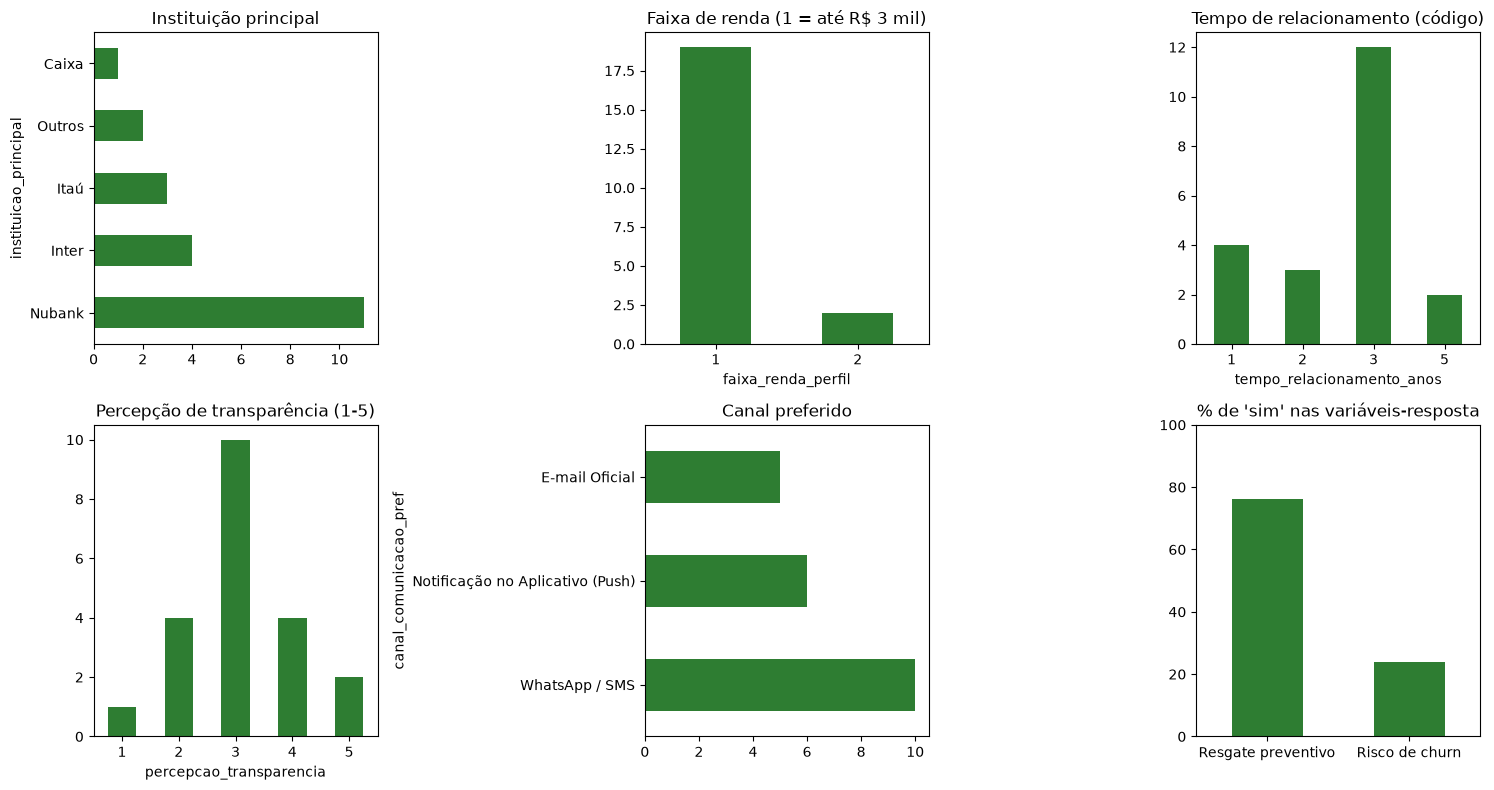

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
cor = "#2e7d32"

df_limpo["instituicao_principal"].value_counts().plot.barh(ax=axes[0, 0], color=cor)
axes[0, 0].set_title("Instituição principal")

df_limpo["faixa_renda_perfil"].value_counts().sort_index().plot.bar(ax=axes[0, 1], color=cor, rot=0)
axes[0, 1].set_title("Faixa de renda (1 = até R$ 3 mil)")

df_limpo["tempo_relacionamento_anos"].value_counts().sort_index().plot.bar(ax=axes[0, 2], color=cor, rot=0)
axes[0, 2].set_title("Tempo de relacionamento (código)")

df_limpo["percepcao_transparencia"].value_counts().sort_index().plot.bar(ax=axes[1, 0], color=cor, rot=0)
axes[1, 0].set_title("Percepção de transparência (1-5)")

df_limpo["canal_comunicacao_pref"].value_counts().plot.barh(ax=axes[1, 1], color=cor)
axes[1, 1].set_title("Canal preferido")

pd.Series({
    "Resgate preventivo": df_limpo["flag_resgate_preventivo"].mean() * 100,
    "Risco de churn": df_limpo["flag_risco_churn"].mean() * 100,
}).plot.bar(ax=axes[1, 2], color=cor, rot=0)
axes[1, 2].set_title("% de 'sim' nas variáveis-resposta")
axes[1, 2].set_ylim(0, 100)

plt.tight_layout()
plt.savefig(FIG_PATH, dpi=150)
plt.show()

### Diagnóstico: o modelo Logit é viável com estes dados?
Regra prática: ~10 eventos para cada variável explicativa. O evento é o menor grupo da variável dependente.

In [8]:
for y in ["flag_risco_churn", "flag_resgate_preventivo"]:
    n1 = int(df_limpo[y].sum())
    n0 = len(df_limpo) - n1
    evento = min(n1, n0)
    print(f"{y}: {n1} sim | {n0} não | evento (grupo menor) = {evento} | variáveis suportadas ~ {evento // 10}")

print()
print("Variação das variáveis de controle (poucos valores distintos = pouca informação):")
print("  renda:", df_limpo["faixa_renda_perfil"].value_counts().to_dict())
print("  bancos:", df_limpo["instituicao_principal"].value_counts().to_dict())

print()
print("Cruzamento transparência x churn:")
pd.crosstab(df_limpo["percepcao_transparencia"], df_limpo["flag_risco_churn"])

flag_risco_churn: 5 sim | 16 não | evento (grupo menor) = 5 | variáveis suportadas ~ 0
flag_resgate_preventivo: 16 sim | 5 não | evento (grupo menor) = 5 | variáveis suportadas ~ 0

Variação das variáveis de controle (poucos valores distintos = pouca informação):
  renda: {1: 19, 2: 2}
  bancos: {'Nubank': 11, 'Inter': 4, 'Itaú': 3, 'Outros': 2, 'Caixa': 1}

Cruzamento transparência x churn:


flag_risco_churn,0,1
percepcao_transparencia,,
1,0,1
2,4,0
3,7,3
4,3,1
5,2,0


## 5. Salvar base limpa
Só colunas necessárias, sem carimbo de data/hora, para reforçar a anonimização (Zero PII).

In [9]:
COLUNAS_FINAIS = [
    "id_respondente", "flag_aceitou_tcle", "instituicao_principal",
    "faixa_renda_perfil", "tempo_relacionamento_anos",
    "percepcao_transparencia", "canal_comunicacao_pref",
    "flag_resgate_preventivo", "flag_risco_churn",
]
df_limpo[COLUNAS_FINAIS].to_csv(OUT_PATH, index=False, encoding="utf-8")
print("Salvo em:", OUT_PATH, "| linhas:", len(df_limpo))

Salvo em: ../data/processed/dados_limpos_anti_gigo.csv | linhas: 21
